<h2>import des bibliothèques</h2>

In [59]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt


import random

from PIL import Image
from glob import glob
from collections import Counter

import torch
import torch.nn as nn
import torch.nn.functional as F

import re, json, random
from collections import defaultdict





import segmentation_models_pytorch as smp
import torch
from torch.utils.data import Dataset, DataLoader




from scipy import ndimage




In [56]:
from collections import defaultdict
import albumentations as A
from albumentations.pytorch import ToTensorV2

MANIFEST = "split_manifest.json"

<h2>Vérification de l'existence et de la structure du dataset RoadAnomaly</h2>

In [51]:


dataset_path = r"<user home>\Documents\deep_learning\RoadAnomaly"
frames_path = os.path.join(dataset_path, "frames")
print("Dossier du dataset :", os.path.exists(dataset_path))
print("Dossier des images :", os.path.exists(frames_path))
MANIFEST = "split_manifest.json"
if os.path.exists(frames_path):
    print("Premiers fichiers :")
    print(os.listdir(frames_path)[:10])

Dossier du dataset : True
Dossier des images : True
Premiers fichiers :
['animals01_Guiguinto_railway_station_Calves.labels', 'animals01_Guiguinto_railway_station_Calves.webp', 'animals02_Zagori_On_the_road_to_Papigko.labels', 'animals02_Zagori_On_the_road_to_Papigko.webp', 'animals03_Zebras_in_the_road.labels', 'animals03_Zebras_in_the_road.webp', 'animals04_17_animal_casualties_so_far_in_2006.labels', 'animals04_17_animal_casualties_so_far_in_2006.webp', 'animals05_cows_near_Phonsavan_Laos.labels', 'animals05_cows_near_Phonsavan_Laos.webp']


<h2>nom des premiers éléments</h2>

In [4]:
files = os.listdir(frames_path)

print("Nombre total de fichiers et dossiers :", len(files))
print("\nPremiers éléments :")

for file in files[:15]:
    print(file)

Nombre total de fichiers et dossiers : 120

Premiers éléments :
animals01_Guiguinto_railway_station_Calves.labels
animals01_Guiguinto_railway_station_Calves.webp
animals02_Zagori_On_the_road_to_Papigko.labels
animals02_Zagori_On_the_road_to_Papigko.webp
animals03_Zebras_in_the_road.labels
animals03_Zebras_in_the_road.webp
animals04_17_animal_casualties_so_far_in_2006.labels
animals04_17_animal_casualties_so_far_in_2006.webp
animals05_cows_near_Phonsavan_Laos.labels
animals05_cows_near_Phonsavan_Laos.webp
animals06_sheep_roads_lambs.labels
animals06_sheep_roads_lambs.webp
animals07_Aihole_Pattadakal.labels
animals07_Aihole_Pattadakal.webp
animals08_on_the_main_street_of_village_Lin_Albania.labels


<h2>Nombre d'images et de masques</h2>

In [5]:


images = sorted(glob(os.path.join(frames_path, "*.webp")))

masks = sorted(
    glob(os.path.join(frames_path, "*.labels", "labels_semantic.png"))
)

print("Nombre d'images :", len(images))
print("Nombre de masques sémantiques :", len(masks))

image_names = {
    os.path.splitext(os.path.basename(path))[0]
    for path in images
}

mask_names = {
    os.path.basename(os.path.dirname(path)).removesuffix(".labels")
    for path in masks
}

print("Images sans masque :", sorted(image_names - mask_names))
print("Masques sans image :", sorted(mask_names - image_names))


Nombre d'images : 60
Nombre de masques sémantiques : 60
Images sans masque : []
Masques sans image : []


In [6]:
# Fonction permettant de retrouver le masque d'une image
def get_mask_path(image_path):
    # Nom de l'image sans son extension
    image_name = os.path.splitext(
        os.path.basename(image_path)
    )[0]

    # Chemin du dossier contenant les annotations
    labels_folder = os.path.join(
        frames_path,
        image_name + ".labels"
    )

    # Chemin du masque sémantique
    return os.path.join(
        labels_folder,
        "labels_semantic.png"
    )


# On conserve uniquement les paires image-masque disponibles
image_pairs = [
    (img, get_mask_path(img))
    for img in images
    if os.path.exists(get_mask_path(img))
]

print("Nombre de paires image-masque :", len(image_pairs))

Nombre de paires image-masque : 60


<h2>Affichage d'un échantillon aléatoire d'images du dataset</h2>



random.seed(42)

sample_images = random.sample(images, min(6, len(images)))

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for ax, image_path in zip(axes, sample_images):
    image = Image.open(image_path).convert("RGB")

    ax.imshow(image)
    ax.set_title(os.path.basename(image_path), fontsize=8)
    ax.axis("off")

for ax in axes[len(sample_images):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

<h2>Chargement et affichage d'une image et de son masque sémantique</h2>

Image : (720, 1280, 3)
Masque : (720, 1280)
Valeurs présentes dans le masque : [0 2]


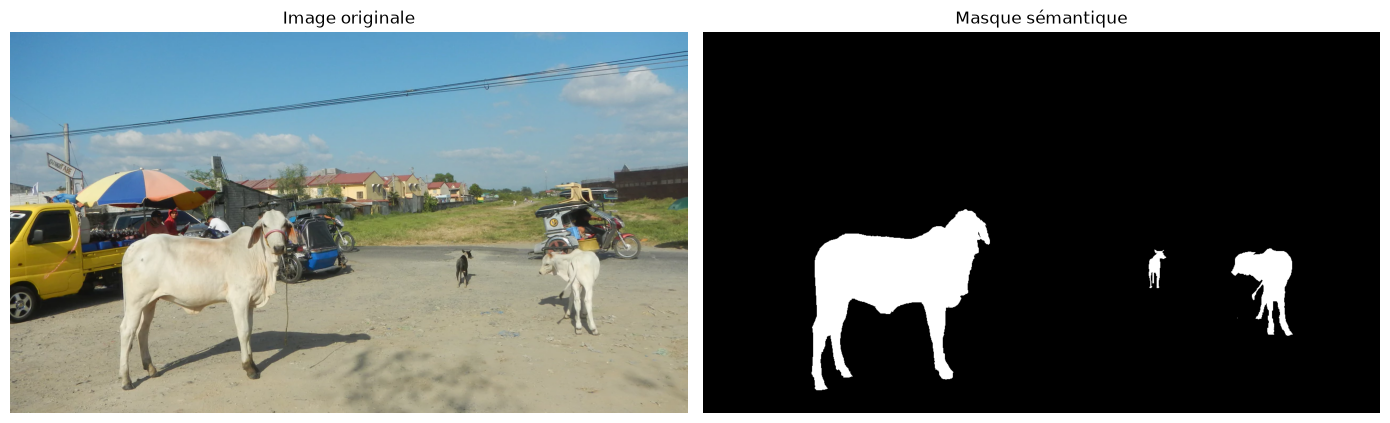

In [7]:


# Choisir une image
image_path = images[0]

# Construire le chemin du masque correspondant
image_name = os.path.splitext(os.path.basename(image_path))[0]

mask_path = os.path.join(
    frames_path,
    image_name + ".labels",
    "labels_semantic.png"
)

# Charger l'image et le masque
image = np.array(Image.open(image_path).convert("RGB"))
mask = np.array(Image.open(mask_path))

print("Image :", image.shape)
print("Masque :", mask.shape)
print("Valeurs présentes dans le masque :", np.unique(mask))

# Affichage côte à côte
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].imshow(image)
axes[0].set_title("Image originale")
axes[0].axis("off")

axes[1].imshow(mask, cmap="gray", vmin=0, vmax=2)
axes[1].set_title("Masque sémantique")
axes[1].axis("off")

plt.tight_layout()
plt.show()

<h2>Superposition des anomalies (masque) sur l'image originale</h2>

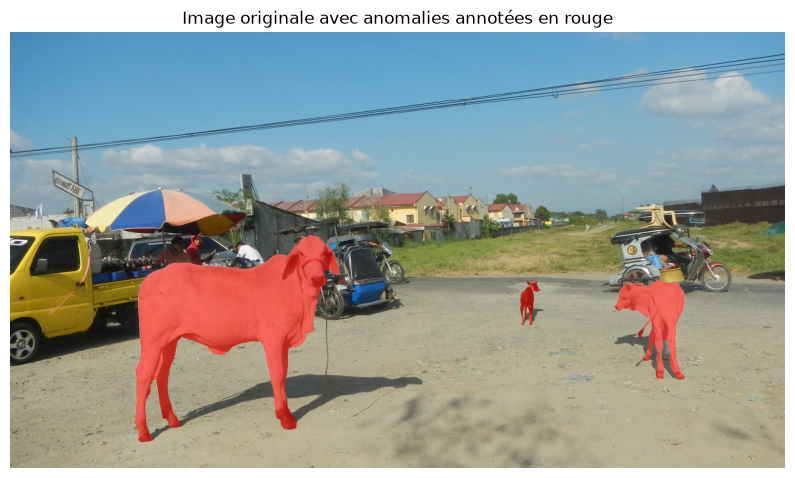

In [8]:
# Les pixels annotés comme anomalies
anomaly_region = mask == 2

# Afficher l'image originale
plt.figure(figsize=(10, 6))
plt.imshow(image)

# Superposer les anomalies en rouge
overlay = np.zeros((*mask.shape, 4))
overlay[anomaly_region] = [1, 0, 0, 0.55]

plt.imshow(overlay)
plt.title("Image originale avec anomalies annotées en rouge")
plt.axis("off")
plt.show()

In [9]:


# Utilisation directe de la variable 'masks' déjà définie dans votre notebook
counts = Counter()

for mask_path in masks:
    mask = np.array(Image.open(mask_path))
    unique, counts_per_class = np.unique(mask, return_counts=True)
    for cls, count in zip(unique, counts_per_class):
        counts[cls] += count

total_pixels = sum(counts.values())

print("--- Distribution globale des pixels par classe ---")
for cls, count in sorted(counts.items()):
    percentage = (count / total_pixels) * 100
    print(f"Classe {cls} : {count:,} pixels ({percentage:.2f}%)")

--- Distribution globale des pixels par classe ---
Classe 0 : 49,849,587 pixels (90.15%)
Classe 2 : 5,446,413 pixels (9.85%)


<h2>Calcul et analyse des statistiques de pixels du masque</h2>

In [10]:
# Nombre total de pixels
total_pixels = mask.size

# Nombre de pixels correspondant aux anomalies
anomaly_pixels = np.sum(mask == 2)

# Nombre de pixels normaux
normal_pixels = np.sum(mask == 0)

print("Nombre total de pixels :", total_pixels)
print("Pixels normaux :", normal_pixels)
print("Pixels anormaux :", anomaly_pixels)

if total_pixels > 0:
    print(
        "Pourcentage de pixels anormaux :",
        round(100 * anomaly_pixels / total_pixels, 2),
        "%"
    )

print("Valeurs uniques du masque :", np.unique(mask))

Nombre total de pixels : 921600
Pixels normaux : 850809
Pixels anormaux : 70791
Pourcentage de pixels anormaux : 7.68 %
Valeurs uniques du masque : [0 2]


<h2>Calcul de la proportion globale d'anomalies sur l'ensemble du jeu de données</h2>

In [11]:
total_anomaly_pixels = 0
total_mask_pixels = 0
images_without_anomaly = 0

for image_path in images:
    name = os.path.splitext(os.path.basename(image_path))[0]

    path = os.path.join(
        frames_path,
        name + ".labels",
        "labels_semantic.png"
    )

    current_mask = np.array(Image.open(path))

    anomaly_count = np.sum(current_mask == 2)

    total_anomaly_pixels += anomaly_count
    total_mask_pixels += current_mask.size

    if anomaly_count == 0:
        images_without_anomaly += 1

print("Images analysées :", len(images))
print("Images sans pixels d'anomalie :", images_without_anomaly)

print(
    "Proportion globale d'anomalies :",
    round(100 * total_anomaly_pixels / total_mask_pixels, 3),
    "%"
)

Images analysées : 60
Images sans pixels d'anomalie : 0
Proportion globale d'anomalies : 9.85 %


<h2>Calcul de la répartition globale des pixels par classe</h2>

In [12]:

class_pixel_counts = Counter()
total_pixels = 0

for image_path, mask_path in image_pairs:
    mask = np.array(Image.open(mask_path))

    values, counts = np.unique(mask, return_counts=True)

    for value, count in zip(values, counts):
        class_pixel_counts[int(value)] += int(count)

    total_pixels += mask.size

print("Répartition globale des classes :\n")

for class_id, count in sorted(class_pixel_counts.items()):
    percentage = 100 * count / total_pixels

    print(
        f"Classe {class_id} : "
        f"{count:,} pixels, "
        f"{percentage:.3f} %"
    )


Répartition globale des classes :

Classe 0 : 49,849,587 pixels, 90.150 %
Classe 2 : 5,446,413 pixels, 9.850 %


<h3 style="color:red">L'analyse de la répartition des pixels montre un fort déséquilibre de classes, avec 90,15 % de fond/route (Classe 0) et seulement 9,85 % d'anomalies (Classe 2).</h3>

In [13]:
dimension_mismatches = []

for image_path in images:
    name = os.path.splitext(os.path.basename(image_path))[0]

    mask_path = os.path.join(
        frames_path,
        name + ".labels",
        "labels_semantic.png"
    )

    if not os.path.exists(mask_path):
        continue

    with Image.open(image_path) as img:
        image_size = img.size

    with Image.open(mask_path) as msk:
        mask_size = msk.size

    if image_size != mask_size:
        dimension_mismatches.append(
            (name, image_size, mask_size)
        )

print("Images avec des dimensions différentes :", dimension_mismatches)

Images avec des dimensions différentes : []


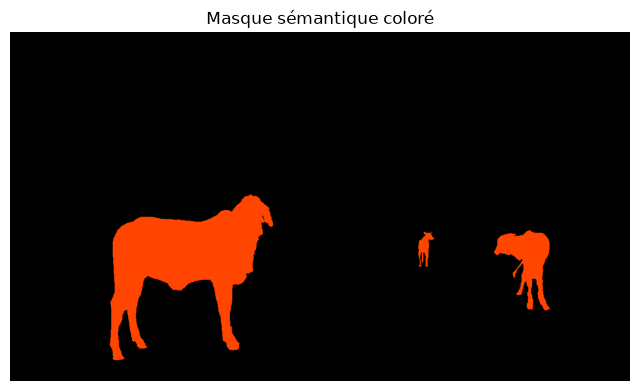

In [14]:
color_mask_path = os.path.join(
    frames_path,
    image_name + ".labels",
    "labels_semantic_color.png"
)

if os.path.exists(color_mask_path):
    color_mask = Image.open(color_mask_path)

    plt.figure(figsize=(8, 5))
    plt.imshow(color_mask)
    plt.title("Masque sémantique coloré")
    plt.axis("off")
    plt.show()

<h2>Distribution de la surface des anomalies par image et statistiques descriptives</h2>

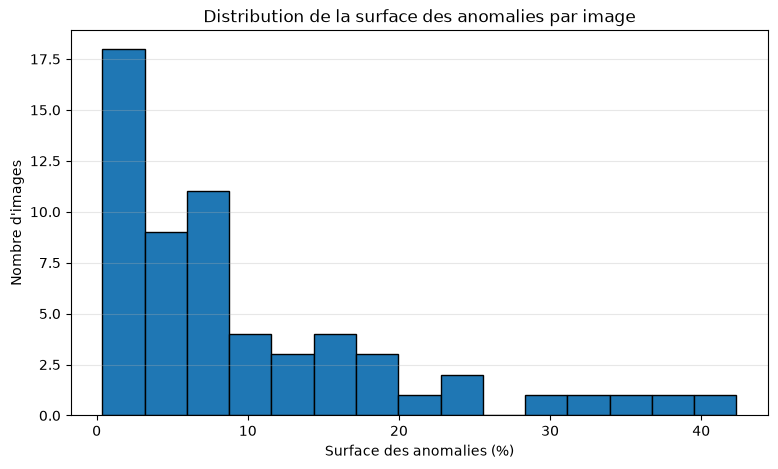

Surface moyenne : 9.85 %
Surface médiane : 6.623 %
Surface minimale : 0.375 %
Surface maximale : 42.329 %
Images avec moins de 0,1 % d'anomalies : 0


In [15]:
# Pourcentage de pixels anormaux dans chaque image
anomaly_percentages = []

for image_path, mask_path in image_pairs:

    # Charger le masque sémantique
    mask = np.array(Image.open(mask_path))

    # Vérifier que le masque est bien une image à une seule couche
    if mask.ndim != 2:
        raise ValueError(
            f"Masque non scalaire : {mask_path}, "
            f"dimensions = {mask.shape}"
        )

    # Créer un masque binaire : True pour une anomalie
    anomaly_mask = (mask == 2)

    # Calculer le pourcentage de pixels anormaux
    percentage = anomaly_mask.sum() / mask.size * 100

    anomaly_percentages.append(percentage)


# Afficher l'histogramme
plt.figure(figsize=(9, 5))

plt.hist(
    anomaly_percentages,
    bins=15,
    edgecolor="black"
)

plt.xlabel("Surface des anomalies (%)")
plt.ylabel("Nombre d'images")
plt.title("Distribution de la surface des anomalies par image")
plt.grid(axis="y", alpha=0.3)

plt.show()


# Quelques statistiques descriptives
print("Surface moyenne :", round(np.mean(anomaly_percentages), 3), "%")
print("Surface médiane :", round(np.median(anomaly_percentages), 3), "%")
print("Surface minimale :", round(np.min(anomaly_percentages), 3), "%")
print("Surface maximale :", round(np.max(anomaly_percentages), 3), "%")
print(
    "Images avec moins de 0,1 % d'anomalies :",
    sum(p < 0.1 for p in anomaly_percentages)
)

<h3 style="color:red">L'analyse de la distribution de la surface des anomalies met en évidence une asymétrie à droite (*right-skewed*), si celle-ci est confirmée par l'histogramme. La surface moyenne des anomalies représente 9,85 % de la surface totale des images, tandis que la médiane est de 6,623 %. Les proportions observées varient entre 0,375 % et 42,329 %, révélant une importante variabilité de la surface occupée par les anomalies d'une image à l'autre.

Ces résultats permettent de caractériser la répartition des anomalies dans le dataset et constituent une première étape pour mieux comprendre les données. Ils seront utiles pour orienter les choix de prétraitement et les décisions liées à la mise en place du modèle de segmentation.</h3>

<h2>Génération et affichage de la carte de chaleur (heatmap) des anomalies</h2>

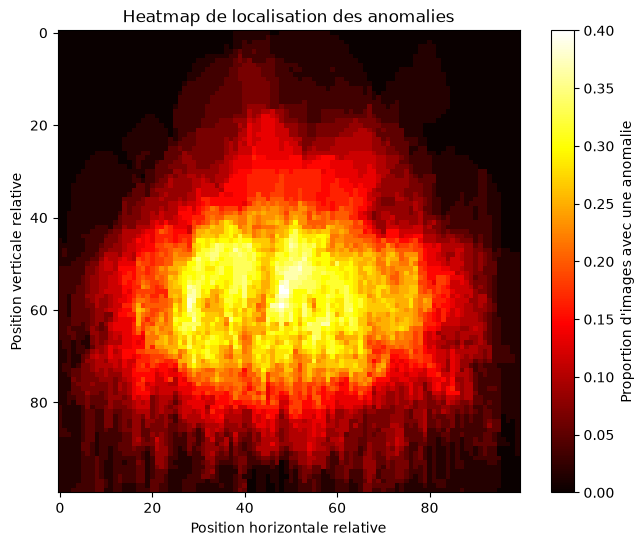

In [16]:

# Taille commune utilisée pour comparer les positions relatives
grid_size = (100, 100)

# Accumulateur des anomalies
heatmap = np.zeros(
    (grid_size[1], grid_size[0]),
    dtype=np.float64
)

for image_path, mask_path in image_pairs:

    # Charger le masque
    mask = Image.open(mask_path)

    # Redimensionner avec NEAREST pour conserver les classes
    mask = mask.resize(
        grid_size,
        resample=Image.Resampling.NEAREST
    )

    mask = np.array(mask)

    # Ajouter les pixels anormaux à la carte
    heatmap += (mask == 2)


# Afficher la heatmap
plt.figure(figsize=(8, 6))

plt.imshow(
    heatmap / max(len(image_pairs), 1),
    cmap="hot",
    origin="upper"
)

plt.colorbar(label="Proportion d'images avec une anomalie")
plt.title("Heatmap de localisation des anomalies")
plt.xlabel("Position horizontale relative")
plt.ylabel("Position verticale relative")

plt.show()

<h3 style="color:red">Cette carte de chaleur (heatmap) superpose l'ensemble des images pour visualiser la position spatiale des obstacles dans le cadre de la photo : la zone brillante (jaune/blanc) au centre montre que la quasi-totalité des anomalies se concentrent sur la chaussée, où près de 40 % des images en contiennent une, tandis que les zones sombres (noires) en haut confirment qu'aucune anomalie n'apparaît dans le ciel ou au niveau du décor haut (0 %).<h3>

In [17]:

image_modes = Counter()

for image_path, mask_path in image_pairs:

    with Image.open(image_path) as img:
        # Enregistrer le mode original avant toute conversion
        image_modes[img.mode] += 1


print("Modes d'image détectés :")

for mode, count in image_modes.items():
    print(f"{mode} : {count} image(s)")


# Vérifier les images possédant un canal alpha
alpha_modes = {"RGBA", "LA", "PA"}

images_with_alpha = []

for image_path, mask_path in image_pairs:

    with Image.open(image_path) as img:
        has_alpha = (
            "A" in img.getbands()
            or "transparency" in img.info
        )

        if has_alpha:
            images_with_alpha.append(image_path)


print("Images avec transparence :", len(images_with_alpha))

for path in images_with_alpha[:10]:
    print(os.path.basename(path))

Modes d'image détectés :
RGB : 60 image(s)
Images avec transparence : 0


<h3 style="color:red">L'analyse des modes d'images confirme que l'ensemble des 60 images du jeu de données utilise le format couleur standard RGB à 3 canaux, sans aucune couche de transparence (canal Alpha / RGBA). Cette parfaite homogénéité garantit qu'aucune conversion de format ou nettoyage préalable ne sera nécessaire avant d'injecter les images dans le pipeline de modélisation.</h3>

<h2>Comptage des composantes connexes et distribution des objets anormaux</h2>

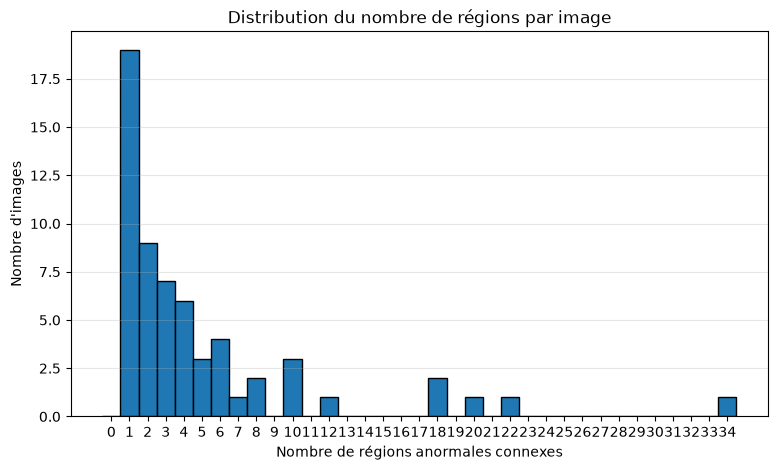

Nombre moyen de régions par image : 4.97


In [18]:

object_counts = []

# Connexité à 8 voisins : les pixels en diagonale sont aussi connectés
structure = np.ones((3, 3), dtype=int)

for image_path, mask_path in image_pairs:

    mask = np.array(Image.open(mask_path))

    # Sélectionner les pixels correspondant aux anomalies
    anomaly_mask = (mask == 2)

    # Identifier les régions connexes
    labeled_mask, number_of_regions = ndimage.label(
        anomaly_mask,
        structure=structure
    )

    object_counts.append(number_of_regions)


# Afficher la distribution du nombre de régions
plt.figure(figsize=(9, 5))

plt.hist(
    object_counts,
    bins=range(0, max(object_counts, default=0) + 2),
    align="left",
    edgecolor="black"
)

plt.xlabel("Nombre de régions anormales connexes")
plt.ylabel("Nombre d'images")
plt.title("Distribution du nombre de régions par image")
plt.xticks(range(0, max(object_counts, default=0) + 1))
plt.grid(axis="y", alpha=0.3)

plt.show()

print("Nombre moyen de régions par image :",
      round(float(np.mean(object_counts)), 2))

<h3 style="color:red">L'analyse de la fragmentation montre que la majorité des images contiennent un seul obstacle d'un seul bloc (19 images), avec une moyenne de 4,97 régions anormales par photo. Cependant, la présence de cas rares mais très complexes — où les anomalies sont éparpillées en plusieurs dizaines de petits morceaux (jusqu'à 34) — confirme que le modèle de segmentation devra être capable de gérer aussi bien des objets uniques et massifs que des obstacles fortement fragmentés.</h3>

<h2>Analyse et distribution du ratio d'aspect (largeur/hauteur) des anomalies</h2>

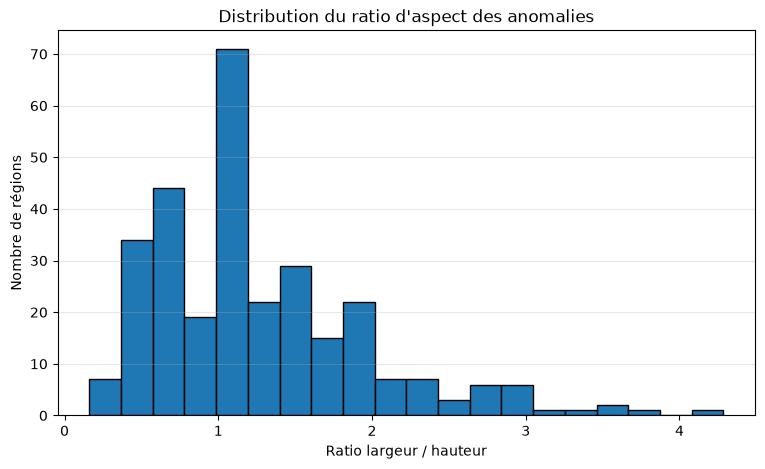

Ratio moyen : 1.25
Ratio médian : 1.0


In [19]:


aspect_ratios = []

structure = np.ones((3, 3), dtype=int)

for image_path, mask_path in image_pairs:

    mask = np.array(Image.open(mask_path))
    anomaly_mask = (mask == 2)

    # Identifier les régions connexes
    labeled_mask, number_of_regions = ndimage.label(
        anomaly_mask,
        structure=structure
    )

    # Extraire les boîtes englobantes de chaque région
    regions = ndimage.find_objects(labeled_mask)

    for region in regions:

        if region is None:
            continue

        # Dimensions de la boîte englobante
        height = region[0].stop - region[0].start
        width = region[1].stop - region[1].start

        if height > 0:
            aspect_ratios.append(width / height)


# Afficher la distribution des ratios
plt.figure(figsize=(9, 5))

plt.hist(
    aspect_ratios,
    bins=20,
    edgecolor="black"
)

plt.xlabel("Ratio largeur / hauteur")
plt.ylabel("Nombre de régions")
plt.title("Distribution du ratio d'aspect des anomalies")
plt.grid(axis="y", alpha=0.3)

plt.show()

if aspect_ratios:
    print("Ratio moyen :",
          round(float(np.mean(aspect_ratios)), 2))
    print("Ratio médian :",
          round(float(np.median(aspect_ratios)), 2))

<h3 style="color:red">L'analyse du ratio d'aspect ($\frac{\text{largeur}}{\text{hauteur}}$) montre que la majorité des régions anormales présentent des proportions équilibrées ou carrées, comme l'indique le pic principal à 1,0 (médiane = 1,0). La moyenne s'élève à 1,25 en raison d'une traînée d'obstacles étalés horizontalement sur la chaussée (ratios allant jusqu'à 4), tandis que les formes très étirées en hauteur (ratios < 1) restent minoritaires.</h3>

Le Pretraitement

In [20]:

random.seed(42)

groups = defaultdict(list)
for img_path, mask_path in image_pairs:
    name = os.path.splitext(os.path.basename(img_path))[0]
    cat = re.match(r"[A-Za-z]+", name).group()
    groups[cat].append((img_path, mask_path))

split = {"train": [], "val": [], "test": []}
for cat, items in groups.items():
    random.shuffle(items)
    n = len(items)
    if n < 3:
        split["train"] += items
        continue
    n_test = max(1, round(0.15 * n))
    n_val = max(1, round(0.15 * n))
    split["test"] += items[:n_test]
    split["val"] += items[n_test:n_test + n_val]
    split["train"] += items[n_test + n_val:]

for k, v in split.items():
    print(k, len(v))

# Manifeste à partager avec le groupe
manifest = {k: [os.path.basename(p[0]) for p in v] for k, v in split.items()}
with open("split_manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)

train 40
val 10
test 10


<h3 style="color:red">Les 60 images sont réparties en 40 pour apprendre (train), 10 pour régler le modèle (validation) et 10 pour le test final. La répartition se fait par catégorie et le split est enregistré dans split_manifest.json, pour que tout le groupe utilise les mêmes images.</h3>

In [21]:


H, W = 288, 512
mean, std = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

train_tf = A.Compose([
    A.Resize(H, W, interpolation=1, mask_interpolation=0),  # image bilinéaire, masque nearest
    A.HorizontalFlip(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.1, rotate_limit=10,
                       border_mode=0, p=0.5),
    A.RandomBrightnessContrast(p=0.3),
    A.Normalize(mean=mean, std=std),
    ToTensorV2(),
])

eval_tf = A.Compose([
    A.Resize(H, W, interpolation=1, mask_interpolation=0),
    A.Normalize(mean=mean, std=std),
    ToTensorV2(),
])

Note: you may need to restart the kernel to use updated packages.


<user home>\anaconda3\Lib\site-packages\albumentations\core\validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


<h3 style="color:red">Les images sont mises à la même taille (288×512) et normalisées. Des petites modifications (flip, rotation, luminosité…) sont ajoutées aux images d'entraînement pour avoir plus de variété. La validation et le test sont seulement redimensionnés et normalisés.</h3>

In [22]:


class RoadAnomalyDataset(Dataset):
    def __init__(self, pairs, transform):
        self.pairs = pairs
        self.transform = transform

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, i):
        img_path, mask_path = self.pairs[i]
        image = np.array(Image.open(img_path).convert("RGB"))
        mask = (np.array(Image.open(mask_path)) == 2).astype(np.uint8)  # binaire 0/1
        out = self.transform(image=image, mask=mask)
        return out["image"], out["mask"].unsqueeze(0).float()  # (3,H,W), (1,H,W)

train_ds = RoadAnomalyDataset(split["train"], train_tf)
val_ds   = RoadAnomalyDataset(split["val"],   eval_tf)
test_ds  = RoadAnomalyDataset(split["test"],  eval_tf)

train_loader = DataLoader(train_ds, batch_size=4, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=4)
test_loader  = DataLoader(test_ds,  batch_size=4)

x, y = next(iter(train_loader))
print(x.shape, y.shape, y.unique())  # attendu : [4,3,288,512] [4,1,288,512] tensor([0.,1.])

torch.Size([4, 3, 288, 512]) torch.Size([4, 1, 288, 512]) tensor([0., 1.])


<h3 style="color:red">Les masques deviennent 0 (fond) et 1 (anomalie). Le DataLoader donne des lots de 4 images : [4, 3, 288, 512] pour les images et [4, 1, 288, 512] pour les masques, avec uniquement les valeurs 0 et 1.</h3>

In [23]:

# Vérifier que le manifeste enregistré correspond au découpage actuel

with open("split_manifest.json", "r", encoding="utf-8") as f:
    manifest = json.load(f)

for group in ["train", "val", "test"]:
    saved_names = set(manifest[group])
    current_names = {
        os.path.basename(img) for img, mask in split[group]
    }

    print(
        group,
        "| manifeste :", len(saved_names),
        "| découpage actuel :", len(current_names),
        "| identiques :", saved_names == current_names
    )


train | manifeste : 40 | découpage actuel : 40 | identiques : True
val | manifeste : 10 | découpage actuel : 10 | identiques : True
test | manifeste : 10 | découpage actuel : 10 | identiques : True


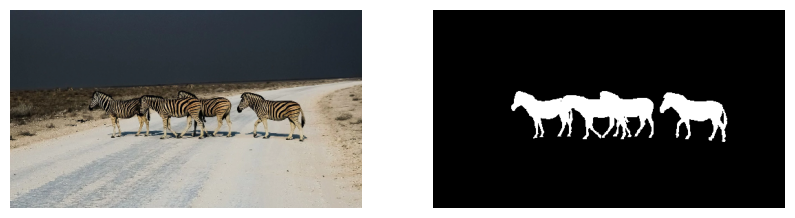

In [24]:
img = x[0].permute(1, 2, 0).numpy() * std + mean
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plt.imshow(img.clip(0, 1)); plt.axis("off")
plt.subplot(1, 2, 2); plt.imshow(y[0, 0], cmap="gray"); plt.axis("off")
plt.show()

<h3 style="color:red">Après l'augmentation, le masque est toujours bien placé sur l'objet. Les petits bords noirs viennent de la rotation. Le prétraitement est correct.</h3>

In [25]:


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)

def block(cin, cout):
    return nn.Sequential(
        nn.Conv2d(cin, cout, 3, padding=1),
        nn.BatchNorm2d(cout),
        nn.ReLU(inplace=True),
    )

class CNNBaseline(nn.Module):
    def __init__(self):
        super().__init__()
        # Encodeur : on rétrécit
        self.enc1 = nn.Sequential(block(3, 16),  nn.MaxPool2d(2))    # 16 x 144 x 256
        self.enc2 = nn.Sequential(block(16, 32), nn.MaxPool2d(2))    # 32 x 72 x 128
        self.enc3 = nn.Sequential(block(32, 64), nn.MaxPool2d(2))    # 64 x 36 x 64
        # Décodeur : on ré-agrandit
        self.dec1 = nn.Sequential(nn.ConvTranspose2d(64, 32, 2, stride=2), block(32, 32))  # 32 x 72 x 128
        self.dec2 = nn.Sequential(nn.ConvTranspose2d(32, 16, 2, stride=2), block(16, 16))  # 16 x 144 x 256
        self.dec3 = nn.Sequential(nn.ConvTranspose2d(16, 8, 2, stride=2),  block(8, 8))    # 8 x 288 x 512
        self.out = nn.Conv2d(8, 1, 1)                                                      # 1 x 288 x 512

    def forward(self, x):
        x = self.enc3(self.enc2(self.enc1(x)))
        x = self.dec3(self.dec2(self.dec1(x)))
        return self.out(x)   # logits (pas de sigmoid ici)

# Loss = BCE + Dice (à cause du déséquilibre 90/10)
bce = nn.BCEWithLogitsLoss()

def dice_loss(logits, targets, eps=1.0):
    p = torch.sigmoid(logits)
    inter = (p * targets).sum(dim=(1, 2, 3))
    union = p.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3))
    return 1 - ((2 * inter + eps) / (union + eps)).mean()

def criterion(logits, targets):
    return bce(logits, targets) + dice_loss(logits, targets)

@torch.no_grad()
def evaluate(model, loader, thr=0.5):
    model.eval()
    tp = fp = fn = 0.0
    total_loss, n = 0.0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        total_loss += criterion(logits, y).item() * x.size(0)
        n += x.size(0)
        pred = (torch.sigmoid(logits) > thr).float()
        tp += (pred * y).sum().item()
        fp += (pred * (1 - y)).sum().item()
        fn += ((1 - pred) * y).sum().item()
    eps = 1e-7
    precision = tp / (tp + fp + eps)
    recall    = tp / (tp + fn + eps)
    f1        = 2 * precision * recall / (precision + recall + eps)
    iou       = tp / (tp + fp + fn + eps)
    dice      = 2 * tp / (2 * tp + fp + fn + eps)
    return {"loss": total_loss / n, "precision": precision, "recall": recall,
            "f1": f1, "iou": iou, "dice": dice}

model = CNNBaseline().to(device)
print(sum(p.numel() for p in model.parameters()), "paramètres")

Device : cpu
46889 paramètres


<h3 style="color:red">Le CNN baseline est un modèle simple (46 889 paramètres) : il réduit l'image puis la ré-agrandit pour dessiner le masque. Il n'a pas de skip connections. La loss BCE + Dice aide à gérer le fait qu'il y a beaucoup plus de fond (90 %) que d'anomalies (10 %).</h3>

In [26]:
import time

torch.manual_seed(42)
EPOCHS, LR = 50, 1e-3
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

history = {"train_loss": [], "val_loss": [], "val_iou": [], "val_dice": []}
best_iou = 0.0
start = time.time()

for epoch in range(1, EPOCHS + 1):
    model.train()
    running, n = 0.0, 0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = criterion(model(x), y)
        loss.backward()
        optimizer.step()
        running += loss.item() * x.size(0)
        n += x.size(0)

    val = evaluate(model, val_loader)
    history["train_loss"].append(running / n)
    history["val_loss"].append(val["loss"])
    history["val_iou"].append(val["iou"])
    history["val_dice"].append(val["dice"])

    if val["iou"] > best_iou:            # meilleur modèle sur la validation
        best_iou = val["iou"]
        torch.save(model.state_dict(), "cnn_baseline_best.pth")

    print(f"Epoch {epoch:02d} | train {running/n:.3f} | val {val['loss']:.3f} "
          f"| IoU {val['iou']:.3f} | Dice {val['dice']:.3f}")

print(f"Durée : {(time.time()-start)/60:.1f} min | meilleur IoU val : {best_iou:.3f}")
print(f"Config : seed=42, résolution={H}x{W}, batch=4, epochs={EPOCHS}, lr={LR}")

Epoch 01 | train 1.687 | val 1.654 | IoU 0.112 | Dice 0.202
Epoch 02 | train 1.619 | val 1.622 | IoU 0.112 | Dice 0.202
Epoch 03 | train 1.567 | val 1.574 | IoU 0.112 | Dice 0.202
Epoch 04 | train 1.536 | val 1.636 | IoU 0.159 | Dice 0.274
Epoch 05 | train 1.512 | val 1.666 | IoU 0.154 | Dice 0.267
Epoch 06 | train 1.497 | val 1.510 | IoU 0.201 | Dice 0.335
Epoch 07 | train 1.483 | val 1.600 | IoU 0.172 | Dice 0.294
Epoch 08 | train 1.463 | val 1.506 | IoU 0.202 | Dice 0.336
Epoch 09 | train 1.440 | val 1.444 | IoU 0.227 | Dice 0.370
Epoch 10 | train 1.422 | val 1.481 | IoU 0.210 | Dice 0.346
Epoch 11 | train 1.410 | val 1.470 | IoU 0.201 | Dice 0.335
Epoch 12 | train 1.397 | val 1.422 | IoU 0.227 | Dice 0.370
Epoch 13 | train 1.379 | val 1.415 | IoU 0.225 | Dice 0.367
Epoch 14 | train 1.369 | val 1.417 | IoU 0.217 | Dice 0.357
Epoch 15 | train 1.337 | val 1.369 | IoU 0.228 | Dice 0.372
Epoch 16 | train 1.332 | val 1.387 | IoU 0.206 | Dice 0.341
Epoch 17 | train 1.315 | val 1.359 | IoU

<h3 style="color:red">Le modèle a appris pendant 50 epochs (7 minutes). La loss baisse, donc il progresse. Le meilleur résultat sur la validation est un IoU de 0,282, et ce modèle est sauvegardé (cnn_baseline_best.pth).</h3>

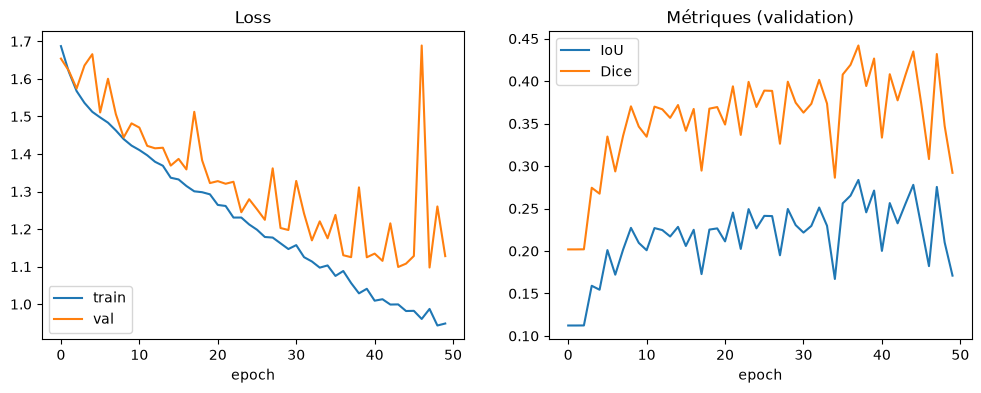

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history["train_loss"], label="train")
ax[0].plot(history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(history["val_iou"], label="IoU")
ax[1].plot(history["val_dice"], label="Dice")
ax[1].set_title("Métriques (validation)"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.show()

<h3 style="color:red">Les loss baissent. L'écart entre train et validation grandit un peu : le modèle commence à trop coller aux images d'entraînement. L'IoU varie beaucoup parce que la validation ne contient que 10 images.</h3>

{'loss': 1.1251, 'precision': 0.4616, 'recall': 0.424, 'f1': 0.442, 'iou': 0.2837, 'dice': 0.442}


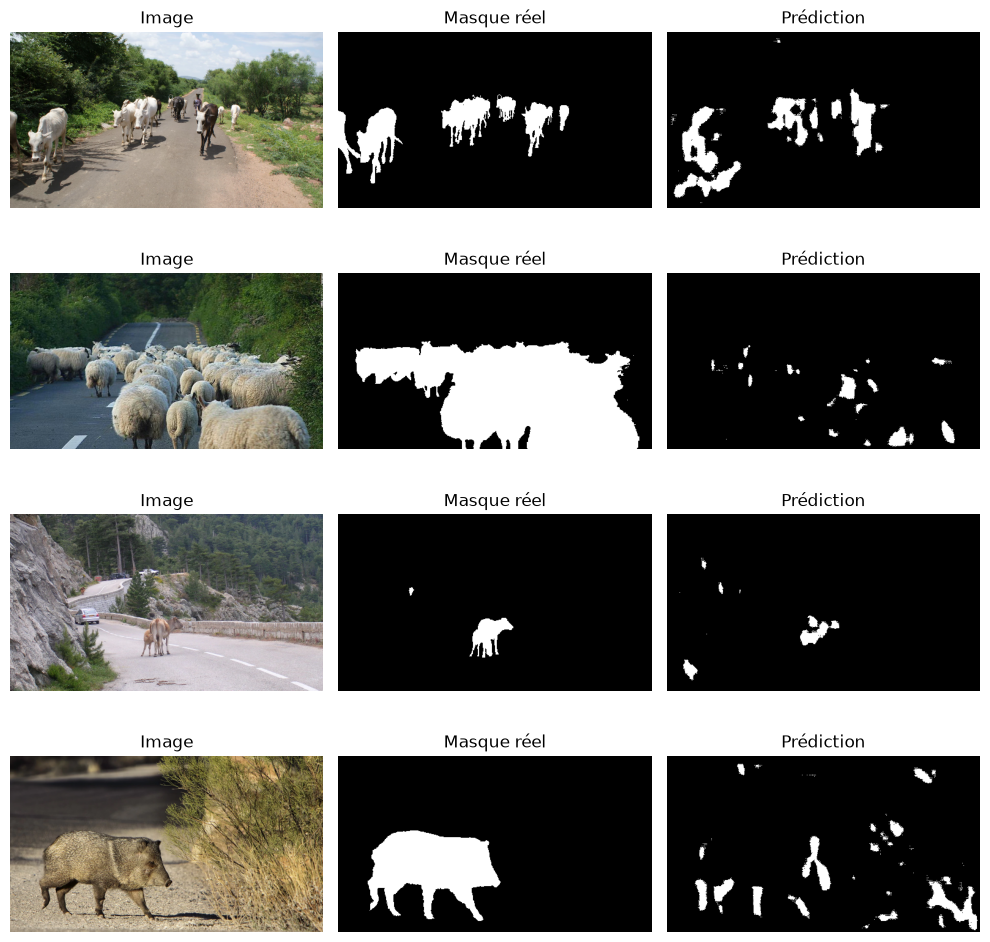

In [28]:
model.load_state_dict(torch.load("cnn_baseline_best.pth"))
res = evaluate(model, val_loader)
print({k: round(v, 4) for k, v in res.items()})

model.eval()
x, y = next(iter(val_loader))
with torch.no_grad():
    pred = (torch.sigmoid(model(x.to(device))) > 0.5).float().cpu()

mean_t, std_t = np.array(mean), np.array(std)
fig, ax = plt.subplots(4, 3, figsize=(10, 10))
for i in range(4):
    img = (x[i].permute(1, 2, 0).numpy() * std_t + mean_t).clip(0, 1)
    ax[i, 0].imshow(img);          ax[i, 0].set_title("Image")
    ax[i, 1].imshow(y[i, 0], cmap="gray");    ax[i, 1].set_title("Masque réel")
    ax[i, 2].imshow(pred[i, 0], cmap="gray"); ax[i, 2].set_title("Prédiction")
    for a in ax[i]: a.axis("off")
plt.tight_layout(); plt.show()

<h3 style="color:red">Sur la validation : Precision 0,426, Recall 0,455, F1 et Dice 0,44, IoU 0,282. Le modèle trouve à peu près où sont les animaux, mais les contours sont flous. Il se trompe sur des rochers et des buissons (faux positifs) et rate des animaux, surtout les petits ou les grands groupes (faux négatifs). C'est normal pour une baseline : le U-Net devra faire mieux. Le test n'a pas encore été utilisé.</h3>

<h1 style="text-align: center;">U-net</h1>

In [60]:
# Bloc de deux convolutions
def double_conv(in_channels, out_channels):

    # nn.Sequential permet d'exécuter plusieurs couches successivement
    return nn.Sequential(

        # Première convolution :
        # in_channels = nombre de canaux en entrée
        # out_channels = nombre de filtres utilisés
        # kernel_size=3 : filtre de convolution de taille 3x3
        # padding=1 : ajoute une bordure pour conserver la même hauteur et largeur
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),

        # Batch Normalization :
        # normalise les valeurs produites par la convolution
        # pour stabiliser et faciliter l'apprentissage
        nn.BatchNorm2d(out_channels),

        # ReLU : fonction d'activation
        # remplace les valeurs négatives par 0
        nn.ReLU(inplace=True),

        # Deuxième convolution :
        # prend les cartes de caractéristiques produites par la première convolution
        # et applique une nouvelle extraction de caractéristiques
        nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),

        # Normalise les résultats de la deuxième convolution
        nn.BatchNorm2d(out_channels),

        # Applique une nouvelle fonction d'activation ReLU
        nn.ReLU(inplace=True)
    )


# Définition de l'architecture du modèle U-Net
class UNet(nn.Module):

    # Constructeur de la classe : initialise les différentes couches du réseau
    def __init__(self):

        # Appelle le constructeur de la classe parent nn.Module
        super().__init__()

        # ==================== ENCODEUR ====================

        # Première étape de l'encodeur :
        # prend une image RGB (3 canaux) et produit 16 cartes de caractéristiques
        self.enc1 = double_conv(3, 16)

        # Deuxième étape :
        # prend 16 canaux et produit 32 cartes de caractéristiques
        self.enc2 = double_conv(16, 32)

        # Troisième étape :
        # prend 32 canaux et produit 64 cartes de caractéristiques
        self.enc3 = double_conv(32, 64)

        # Quatrième étape :
        # prend 64 canaux et produit 128 cartes de caractéristiques
        self.enc4 = double_conv(64, 128)

        # MaxPooling :
        # réduit la hauteur et la largeur de l'image par 2
        # permet de réduire la taille des données et de conserver les caractéristiques importantes
        self.pool = nn.MaxPool2d(2)

        # ==================== BOTTLENECK ====================

        # Partie centrale du U-Net :
        # prend 128 canaux et produit 256 cartes de caractéristiques
        # cette partie travaille sur une représentation plus compacte de l'image
        self.bottleneck = double_conv(128, 256)

        # ==================== DÉCODEUR ====================

        # Première opération de remontée :
        # ConvTranspose2d augmente la hauteur et la largeur par 2
        # et transforme les 256 canaux en 128 canaux
        self.up4 = nn.ConvTranspose2d(256, 128, 2, stride=2)

        # Bloc de convolution :
        # reçoit 256 canaux (128 venant de up4 + 128 venant de l'encodeur)
        # et produit 128 canaux
        self.dec4 = double_conv(256, 128)

        # Deuxième remontée :
        # augmente les dimensions par 2 et transforme 128 canaux en 64
        self.up3 = nn.ConvTranspose2d(128, 64, 2, stride=2)

        # Reçoit 128 canaux après la concaténation :
        # 64 du décodeur + 64 de l'encodeur
        # puis produit 64 canaux
        self.dec3 = double_conv(128, 64)

        # Troisième remontée :
        # augmente les dimensions par 2 et transforme 64 canaux en 32
        self.up2 = nn.ConvTranspose2d(64, 32, 2, stride=2)

        # Reçoit 64 canaux :
        # 32 du décodeur + 32 de l'encodeur
        # puis produit 32 canaux
        self.dec2 = double_conv(64, 32)

        # Quatrième remontée :
        # augmente les dimensions par 2 et transforme 32 canaux en 16
        self.up1 = nn.ConvTranspose2d(32, 16, 2, stride=2)

        # Reçoit 32 canaux :
        # 16 du décodeur + 16 de l'encodeur
        # puis produit 16 canaux
        self.dec1 = double_conv(32, 16)

        # ==================== COUCHE DE SORTIE ====================

        # Convolution finale :
        # transforme les 16 canaux en un seul canal
        # kernel_size=1 : utilise un filtre de taille 1x1
        # ce canal contient un score pour chaque pixel de l'image
        self.out = nn.Conv2d(16, 1, kernel_size=1)

    # Méthode appelée automatiquement lorsqu'on utilise le modèle sur une image
    def forward(self, x):

        # ==================== ENCODEUR ====================

        # Applique le premier bloc de convolution à l'image d'entrée
        # e1 contient les caractéristiques extraites à la première étape
        e1 = self.enc1(x)

        # Réduit les dimensions de e1 par MaxPooling
        # puis applique le deuxième bloc de convolution
        e2 = self.enc2(self.pool(e1))

        # Réduit les dimensions de e2 par MaxPooling
        # puis applique le troisième bloc de convolution
        e3 = self.enc3(self.pool(e2))

        # Réduit les dimensions de e3 par MaxPooling
        # puis applique le quatrième bloc de convolution
        e4 = self.enc4(self.pool(e3))

        # ==================== BOTTLENECK ====================

        # Réduit les dimensions de e4 par MaxPooling
        # puis applique le bloc central du réseau
        b = self.bottleneck(self.pool(e4))

        # ==================== DÉCODEUR + SKIP CONNECTIONS ====================

        # Augmente les dimensions de b par 2
        # le résultat possède 128 canaux
        d4 = self.up4(b)

        # Skip Connection :
        # concatène les caractéristiques du décodeur (d4)
        # avec celles de l'encodeur (e4)
        # dim=1 indique que la concaténation se fait sur les canaux
        d4 = torch.cat([d4, e4], dim=1)

        # Applique le bloc de convolution après la concaténation
        d4 = self.dec4(d4)

        # Augmente les dimensions de d4 par 2
        d3 = self.up3(d4)

        # Concatène les caractéristiques du décodeur avec celles de l'encodeur e3
        d3 = torch.cat([d3, e3], dim=1)

        # Traite les caractéristiques concaténées
        d3 = self.dec3(d3)

        # Augmente les dimensions de d3 par 2
        d2 = self.up2(d3)

        # Concatène les caractéristiques du décodeur avec celles de l'encodeur e2
        d2 = torch.cat([d2, e2], dim=1)

        # Traite les caractéristiques concaténées
        d2 = self.dec2(d2)

        # Augmente les dimensions de d2 par 2
        d1 = self.up1(d2)

        # Concatène les caractéristiques du décodeur avec celles de l'encodeur e1
        d1 = torch.cat([d1, e1], dim=1)

        # Applique le dernier bloc de convolution
        d1 = self.dec1(d1)

        # ==================== RÉSULTAT FINAL ====================

        # Applique la convolution finale pour obtenir un seul canal
        # contenant les logits de segmentation pour chaque pixel
        return self.out(d1)

In [30]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device utilisé :", device)

Device utilisé : cpu


In [31]:
# Création du modèle U-Net
unet_model = UNet().to(device)

# Récupération d'un batch de données
x, y = next(iter(train_loader))

# Passage du batch sur le même device que le modèle
x = x.to(device)
y = y.to(device)

# Vérification de la sortie du modèle
unet_model.eval()

with torch.no_grad():
    output = unet_model(x)

# Affichage des dimensions
print("Image :", x.shape)
print("Masque réel :", y.shape)
print("Sortie U-Net :", output.shape)

# Nombre total de paramètres
total_params = sum(p.numel() for p in unet_model.parameters())
print("Nombre de paramètres :", total_params)

# Vérification de la compatibilité des dimensions
assert output.shape == y.shape, "Erreur : les dimensions de la sortie et du masque sont différentes !"

print("Vérification réussie : les dimensions sont compatibles.")

Image : torch.Size([4, 3, 288, 512])
Masque réel : torch.Size([4, 1, 288, 512])
Sortie U-Net : torch.Size([4, 1, 288, 512])
Nombre de paramètres : 1944049
Vérification réussie : les dimensions sont compatibles.


In [32]:

import time

torch.manual_seed(42)

EPOCHS = 50
LR = 1e-3

optimizer_unet = torch.optim.Adam(
    unet_model.parameters(),
    lr=LR
)

history_unet = {
    "train_loss": [],
    "val_loss": [],
    "val_iou": [],
    "val_dice": []
}

best_iou_unet = 0.0

start = time.time()

for epoch in range(1, EPOCHS + 1):

    unet_model.train()

    running_loss = 0.0
    n = 0

    for x, y in train_loader:

        x = x.to(device)
        y = y.to(device)

        optimizer_unet.zero_grad()

        logits = unet_model(x)
        loss = criterion(logits, y)

        loss.backward()
        optimizer_unet.step()

        running_loss += loss.item() * x.size(0)
        n += x.size(0)

    # Évaluation sur validation
    val = evaluate(unet_model, val_loader)

    train_loss = running_loss / n

    history_unet["train_loss"].append(train_loss)
    history_unet["val_loss"].append(val["loss"])
    history_unet["val_iou"].append(val["iou"])
    history_unet["val_dice"].append(val["dice"])

    # Sauvegarder le meilleur modèle
    if val["iou"] > best_iou_unet:

        best_iou_unet = val["iou"]

        torch.save(
            unet_model.state_dict(),
            "unet_best.pth"
        )

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {train_loss:.3f} | "
        f"Val Loss: {val['loss']:.3f} | "
        f"IoU: {val['iou']:.3f} | "
        f"Dice: {val['dice']:.3f}"
    )

print(
    f"\nDurée : {(time.time()-start)/60:.1f} min"
)

print("Meilleur IoU validation :", best_iou_unet)


Epoch 01 | Train Loss: 1.490 | Val Loss: 1.494 | IoU: 0.038 | Dice: 0.074
Epoch 02 | Train Loss: 1.382 | Val Loss: 1.698 | IoU: 0.146 | Dice: 0.255
Epoch 03 | Train Loss: 1.336 | Val Loss: 1.405 | IoU: 0.236 | Dice: 0.381
Epoch 04 | Train Loss: 1.289 | Val Loss: 1.379 | IoU: 0.250 | Dice: 0.400
Epoch 05 | Train Loss: 1.269 | Val Loss: 1.360 | IoU: 0.243 | Dice: 0.392
Epoch 06 | Train Loss: 1.256 | Val Loss: 1.476 | IoU: 0.229 | Dice: 0.373
Epoch 07 | Train Loss: 1.252 | Val Loss: 1.471 | IoU: 0.227 | Dice: 0.370
Epoch 08 | Train Loss: 1.219 | Val Loss: 1.250 | IoU: 0.256 | Dice: 0.407
Epoch 09 | Train Loss: 1.195 | Val Loss: 1.528 | IoU: 0.199 | Dice: 0.333
Epoch 10 | Train Loss: 1.173 | Val Loss: 1.305 | IoU: 0.247 | Dice: 0.396
Epoch 11 | Train Loss: 1.164 | Val Loss: 1.222 | IoU: 0.239 | Dice: 0.386
Epoch 12 | Train Loss: 1.135 | Val Loss: 1.265 | IoU: 0.252 | Dice: 0.402
Epoch 13 | Train Loss: 1.130 | Val Loss: 1.665 | IoU: 0.206 | Dice: 0.342
Epoch 14 | Train Loss: 1.114 | Val Los

In [33]:
# Charger le meilleur modèle selon l'IoU de validation
unet_model.load_state_dict(
    torch.load("unet_best.pth", map_location=device)
)

unet_model.eval()

print("Meilleur modèle U-Net chargé avec succès.")

Meilleur modèle U-Net chargé avec succès.


In [34]:
# Évaluation finale sur le test
unet_test_results = evaluate(unet_model, test_loader)

print("Résultats U-Net sur le jeu de test :")

for metric, value in unet_test_results.items():
    print(f"{metric} : {value:.4f}")

Résultats U-Net sur le jeu de test :
loss : 0.8732
precision : 0.5597
recall : 0.4508
f1 : 0.4994
iou : 0.3328
dice : 0.4994


<h3>Amélioration du modèle</h3>

In [42]:
import segmentation_models_pytorch as smp

def build_model():
    return smp.Unet(
        encoder_name="resnet34",        # encodeur pré-entraîné
        encoder_weights="imagenet",     # poids ImageNet (téléchargés au 1er lancement)
        in_channels=3,
        classes=1,                      # segmentation binaire
        activation=None                 # on garde des logits (comme avant)
    ).to(device)

unet_pre = build_model()
print(sum(p.numel() for p in unet_pre.parameters()) / 1e6, "M paramètres")

# Vérification des dimensions (288 et 512 sont divisibles par 32 : OK pour ResNet)
x, y = next(iter(train_loader))
with torch.no_grad():
    print(unet_pre.eval()(x.to(device)).shape)   # attendu : [4, 1, 288, 512]

24.436369 M paramètres
torch.Size([8, 1, 288, 512])


<h3 style="color:red"> =>U-Net avec encodeur ResNet34 pré-entraîné sur ImageNet<br/>
Idéal pour de petits jeux de données
</h3>

In [43]:
def focal_loss(logits, targets, gamma=2.0):
    bce_pix = F.binary_cross_entropy_with_logits(logits, targets, reduction="none")
    pt = torch.exp(-bce_pix)
    return ((1 - pt) ** gamma * bce_pix).mean()

def tversky_loss(logits, targets, alpha=0.3, beta=0.7, gamma=0.75, eps=1.0):
    p = torch.sigmoid(logits)
    tp = (p * targets).sum(dim=(1, 2, 3))
    fp = (p * (1 - targets)).sum(dim=(1, 2, 3))
    fn = ((1 - p) * targets).sum(dim=(1, 2, 3))
    t = (tp + eps) / (tp + alpha * fp + beta * fn + eps)
    return ((1 - t) ** gamma).mean()

# On redéfinit `criterion` : la fonction evaluate() l'utilisera automatiquement
def criterion(logits, targets):
    return focal_loss(logits, targets) + tversky_loss(logits, targets)

<h3 style="color:red"> =>focal_loss: Forcer le modèle à se concentrer sur les pixels bordures et les détails durs à détecter au lieu de perdre son temps sur le fond facile.<br/>
tversky_loss : Réduire les oublis pour corriger le manque de Recall
</h3>

In [44]:
train_tf2 = A.Compose([
    A.Resize(H, W, interpolation=1, mask_interpolation=0),
    A.HorizontalFlip(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.08, scale_limit=0.25, rotate_limit=15,
                       border_mode=0, p=0.6),
    A.RandomBrightnessContrast(p=0.4),
    A.HueSaturationValue(p=0.3),
    A.RandomGamma(p=0.3),
    A.GaussianBlur(blur_limit=(3, 5), p=0.2),
    A.Normalize(mean=mean, std=std),
    ToTensorV2(),
])

train_ds2 = RoadAnomalyDataset(split["train"], train_tf2)
train_loader = DataLoader(train_ds2, batch_size=8, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=8)
test_loader  = DataLoader(test_ds,  batch_size=8)

<h3 style="color:red"> => envoyer les images par paquets de 8 images<br/>
    Un batch_size=4 consomme moins de mémoire GPU, ce qui est plus sûr pour éviter les erreurs OutOfMemory.<br/>

En contrepartie, un batch_size=8 permet un calcul de gradient un peu plus stable et accélère légèrement le temps d'entraînement si la mémoire GPU le permet.
</h3>

In [45]:
import time

def train_model(model, name, epochs=80, lr=3e-4, patience=15):
    torch.manual_seed(42)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)

    history = {"train_loss": [], "val_loss": [], "val_iou": [], "val_dice": []}
    best_iou, best_epoch, start = 0.0, 0, time.time()

    for epoch in range(1, epochs + 1):
        model.train()
        running, n = 0.0, 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            loss = criterion(model(x), y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)   # gradient clipping
            optimizer.step()
            running += loss.item() * x.size(0)
            n += x.size(0)
        scheduler.step()

        val = evaluate(model, val_loader)
        history["train_loss"].append(running / n)
        history["val_loss"].append(val["loss"])
        history["val_iou"].append(val["iou"])
        history["val_dice"].append(val["dice"])

        if val["iou"] > best_iou:
            best_iou, best_epoch = val["iou"], epoch
            torch.save(model.state_dict(), f"{name}_best.pth")

        print(f"Epoch {epoch:02d} | train {running/n:.3f} | val {val['loss']:.3f} "
              f"| IoU {val['iou']:.3f} | Dice {val['dice']:.3f}")

        if epoch - best_epoch >= patience:                 # early stopping
            print(f"Arrêt anticipé à l'epoch {epoch} (meilleure : {best_epoch})")
            break

    print(f"Durée : {(time.time()-start)/60:.1f} min | meilleur IoU val : {best_iou:.3f}")
    return history

history_pre = train_model(unet_pre, "unet_resnet34")

Epoch 01 | train 1.220 | val 2.139 | IoU 0.114 | Dice 0.205
Epoch 02 | train 0.989 | val 1.902 | IoU 0.124 | Dice 0.221
Epoch 03 | train 0.925 | val 1.266 | IoU 0.170 | Dice 0.291
Epoch 04 | train 0.872 | val 1.160 | IoU 0.300 | Dice 0.461
Epoch 05 | train 0.835 | val 0.872 | IoU 0.446 | Dice 0.616
Epoch 06 | train 0.813 | val 0.829 | IoU 0.524 | Dice 0.688
Epoch 07 | train 0.811 | val 0.822 | IoU 0.499 | Dice 0.665
Epoch 08 | train 0.775 | val 0.790 | IoU 0.596 | Dice 0.747
Epoch 09 | train 0.750 | val 0.776 | IoU 0.618 | Dice 0.764
Epoch 10 | train 0.730 | val 0.759 | IoU 0.669 | Dice 0.801
Epoch 11 | train 0.725 | val 0.767 | IoU 0.632 | Dice 0.774
Epoch 12 | train 0.711 | val 0.746 | IoU 0.659 | Dice 0.794
Epoch 13 | train 0.723 | val 0.750 | IoU 0.597 | Dice 0.748
Epoch 14 | train 0.694 | val 0.786 | IoU 0.492 | Dice 0.660
Epoch 15 | train 0.686 | val 0.805 | IoU 0.439 | Dice 0.610
Epoch 16 | train 0.696 | val 0.817 | IoU 0.393 | Dice 0.564
Epoch 17 | train 0.659 | val 0.749 | IoU

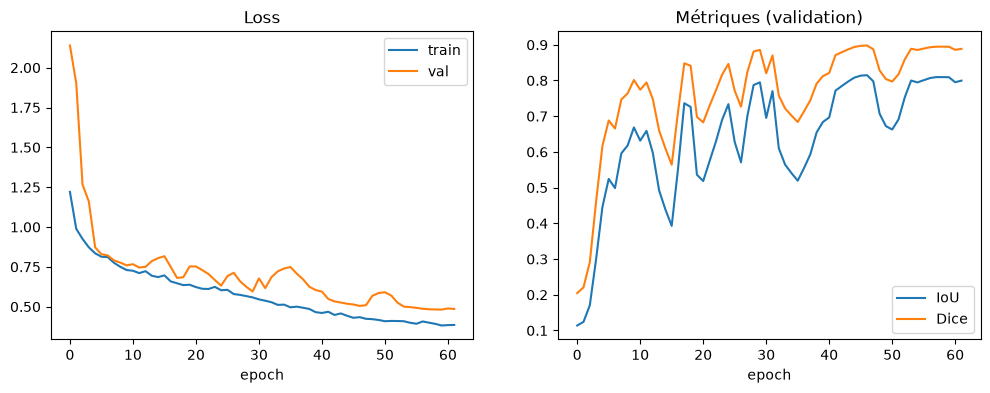

In [46]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history_pre["train_loss"], label="train")
ax[0].plot(history_pre["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(history_pre["val_iou"], label="IoU")
ax[1].plot(history_pre["val_dice"], label="Dice")
ax[1].set_title("Métriques (validation)"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.show()

In [47]:
unet_pre.load_state_dict(torch.load("unet_resnet34_best.pth", map_location=device))
unet_pre.eval()

@torch.no_grad()
def get_probs(model, loader, tta=True):
    model.eval()
    P, Y = [], []
    for x, y in loader:
        x = x.to(device)
        p = torch.sigmoid(model(x))
        if tta:   # moyenne avec la prédiction sur l'image retournée
            p2 = torch.sigmoid(model(torch.flip(x, dims=[3])))
            p = (p + torch.flip(p2, dims=[3])) / 2
        P.append(p.cpu()); Y.append(y)
    return torch.cat(P), torch.cat(Y)

def scores(P, Y, thr):
    pred = (P > thr).float()
    tp = (pred * Y).sum().item()
    fp = (pred * (1 - Y)).sum().item()
    fn = ((1 - pred) * Y).sum().item()
    eps = 1e-7
    prec = tp / (tp + fp + eps)
    rec  = tp / (tp + fn + eps)
    return {"precision": prec, "recall": rec,
            "iou": tp / (tp + fp + fn + eps),
            "dice": 2 * tp / (2 * tp + fp + fn + eps)}

# 1) Recherche du meilleur seuil sur la VALIDATION
P_val, Y_val = get_probs(unet_pre, val_loader, tta=True)
thresholds = np.arange(0.2, 0.81, 0.05)
val_scores = [scores(P_val, Y_val, t) for t in thresholds]
best_thr = thresholds[int(np.argmax([s["dice"] for s in val_scores]))]

for t, s in zip(thresholds, val_scores):
    print(f"seuil {t:.2f} | IoU {s['iou']:.3f} | Dice {s['dice']:.3f}")
print("\nMeilleur seuil (validation) :", round(float(best_thr), 2))

# 2) Évaluation finale sur le TEST avec ce seuil
P_test, Y_test = get_probs(unet_pre, test_loader, tta=True)
test_final = scores(P_test, Y_test, best_thr)
print("\nU-Net ResNet34 | TEST :", {k: round(v, 4) for k, v in test_final.items()})

seuil 0.20 | IoU 0.777 | Dice 0.874
seuil 0.25 | IoU 0.792 | Dice 0.884
seuil 0.30 | IoU 0.800 | Dice 0.889
seuil 0.35 | IoU 0.807 | Dice 0.893
seuil 0.40 | IoU 0.813 | Dice 0.897
seuil 0.45 | IoU 0.818 | Dice 0.900
seuil 0.50 | IoU 0.822 | Dice 0.903
seuil 0.55 | IoU 0.823 | Dice 0.903
seuil 0.60 | IoU 0.824 | Dice 0.903
seuil 0.65 | IoU 0.823 | Dice 0.903
seuil 0.70 | IoU 0.823 | Dice 0.903
seuil 0.75 | IoU 0.821 | Dice 0.902
seuil 0.80 | IoU 0.819 | Dice 0.900

Meilleur seuil (validation) : 0.6

U-Net ResNet34 | TEST : {'precision': 0.91, 'recall': 0.7879, 'iou': 0.731, 'dice': 0.8446}


<h3 style="color:red"> => Récupérer le meilleur modèle entraîné. <br/>
    Faire deux prédictions avec TTA et les combiner.<br/>
    Trouver le seuil qui donne le meilleur Dice sur la validation.<br/>
    Tester le modèle avec ce seuil sur les données de test.<br/>
</h3>

In [48]:
print("Comparaison sur le TEST")
print(f"U-Net initial          | IoU {unet_test_results['iou']:.3f} | Dice {unet_test_results['dice']:.3f}")
print(f"U-Net ResNet34 + tout  | IoU {test_final['iou']:.3f} | Dice {test_final['dice']:.3f}")

# IoU par image : identifie les images où le modèle échoue
pred = (P_test > best_thr).float()
for i in range(len(pred)):
    inter = (pred[i] * Y_test[i]).sum().item()
    union = ((pred[i] + Y_test[i]) > 0).float().sum().item()
    print(f"Image test {i:02d} | IoU {inter / (union + 1e-7):.3f}")

Comparaison sur le TEST
U-Net initial          | IoU 0.333 | Dice 0.499
U-Net ResNet34 + tout  | IoU 0.731 | Dice 0.845
Image test 00 | IoU 0.864
Image test 01 | IoU 0.766
Image test 02 | IoU 0.790
Image test 03 | IoU 0.807
Image test 04 | IoU 0.918
Image test 05 | IoU 0.449
Image test 06 | IoU 0.514
Image test 07 | IoU 0.599
Image test 08 | IoU 0.766
Image test 09 | IoU 0.722


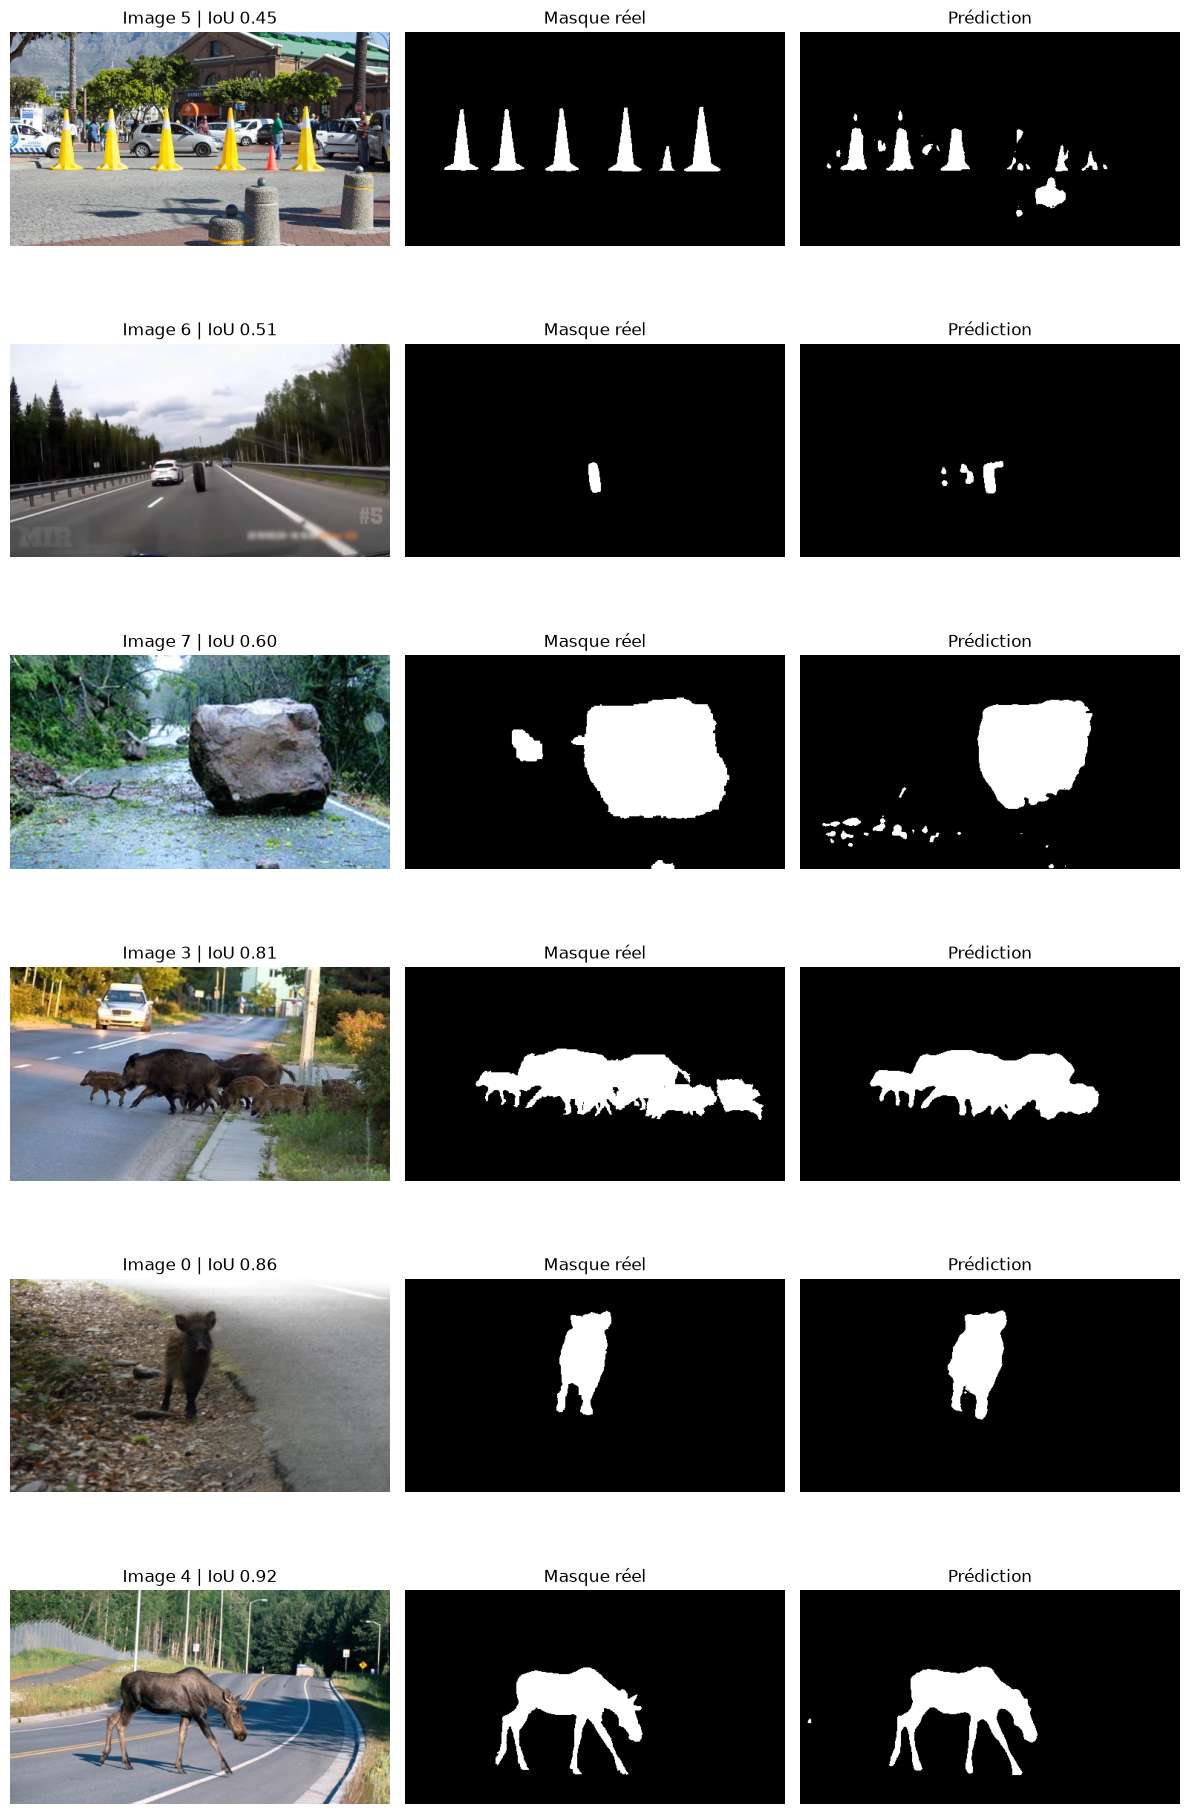

In [49]:
# Récupérer les images de test dans le même ordre que P_test (shuffle=False)
imgs = torch.cat([x for x, _ in test_loader])

def denorm(img):
    m = torch.tensor(mean).view(3, 1, 1)
    s = torch.tensor(std).view(3, 1, 1)
    return (img * s + m).clamp(0, 1).permute(1, 2, 0).numpy()

# IoU par image
ious = []
for i in range(len(pred)):
    inter = (pred[i] * Y_test[i]).sum().item()
    union = ((pred[i] + Y_test[i]) > 0).float().sum().item()
    ious.append(inter / (union + 1e-7))

order = np.argsort(ious)
chosen = list(order[:3]) + list(order[-3:])   # 3 pires + 3 meilleures

fig, axes = plt.subplots(len(chosen), 3, figsize=(12, 3.2 * len(chosen)))
for r, i in enumerate(chosen):
    axes[r, 0].imshow(denorm(imgs[i]));                 axes[r, 0].set_title(f"Image {i} | IoU {ious[i]:.2f}")
    axes[r, 1].imshow(Y_test[i, 0], cmap="gray");       axes[r, 1].set_title("Masque réel")
    axes[r, 2].imshow(pred[i, 0], cmap="gray");         axes[r, 2].set_title("Prédiction")
    for a in axes[r]: a.axis("off")
plt.tight_layout(); plt.show()